In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt #per plot
import seaborn as sns #per plot

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_val_predict, StratifiedKFold, train_test_split

from sklearn.utils import resample
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier      #Algoritmo KNN
from sklearn.linear_model import LogisticRegression     #Regressione logistica
from sklearn.ensemble import RandomForestClassifier     #Random Forest
from sklearn.decomposition import PCA #pca



# Per riproducibilità
RANDOM_STATE = 353244
np.random.seed(RANDOM_STATE)


# Caricamento dati ed analisi preliminari

In [3]:
train_path = "wine_train.xlsx"
test_path = "wine_test.xlsx"

train_data = pd.read_excel(train_path)
test_data = pd.read_excel(test_path)

##### Funzioni per i plots dei dati

In [4]:
cols_to_drop = ['WineQuality', 'Synthetic_Noise_Flag', 'Volatile_Enhanced']


def plot_distribuzioni(df, cols_to_drop):
    features = [c for c in df.columns if c not in cols_to_drop]

    # Costruzione della griglia
    num_features = len(features)
    num_cols = 4
    num_rows = math.ceil(num_features / num_cols)
    plt.figure(figsize=(20, num_rows * 4))

    for i, col in enumerate(features):
        plt.subplot(num_rows, num_cols, i + 1)
        sns.histplot(df[col], kde=True, color='teal', bins=30)
        plt.title(f'Distr: {col}', fontsize=12, fontweight='bold')
        plt.xlabel('')
        plt.ylabel('')

    plt.tight_layout()
    plt.show()


def plot_chemical_features_enhanced(df, cols_to_drop, target_col='WineQuality'):
    # Setup stile Seaborn
    sns.set_theme(style="whitegrid")
    
    # Selezione feature
    features = [c for c in df.columns if c not in cols_to_drop]
    n_features = len(features)
    n_cols = 5 
    n_rows = math.ceil(n_features / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
    axes = axes.flatten()
    
    for i, feature in enumerate(features):
        ax = axes[i]
        
        # Boxplot di fondo per mostrare i quantili (senza outlier)
        sns.boxplot(
            data=df, x=target_col, y=feature, 
            ax=ax, hue=target_col, palette='viridis', 
            showfliers=False, boxprops=dict(alpha=0.3),
            legend=False
        )
        
        # Stripplot per mostrare la densità dei dati
        sns.stripplot(
            data=df, x=target_col, y=feature, 
            ax=ax, hue=target_col, palette='viridis',
            jitter=True, alpha=0.5, size=3, dodge=False
        )
        
        # Pulizia del plot
        ax.set_title(f'{feature.replace("_", " ").title()}', fontsize=14, fontweight='bold', pad=10)
        ax.set_xlabel('Wine Quality', fontsize=11)
        ax.set_ylabel('Value', fontsize=11)
        ax.legend([], [], frameon=False) # Rimuove leggenda ridondante
        
    # Rimozione subplot in eccesso dalla figure
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()



#### Grafici PRE-pulizia e POST-pulizia


Grafico dati originali, senza alcuna pulizia


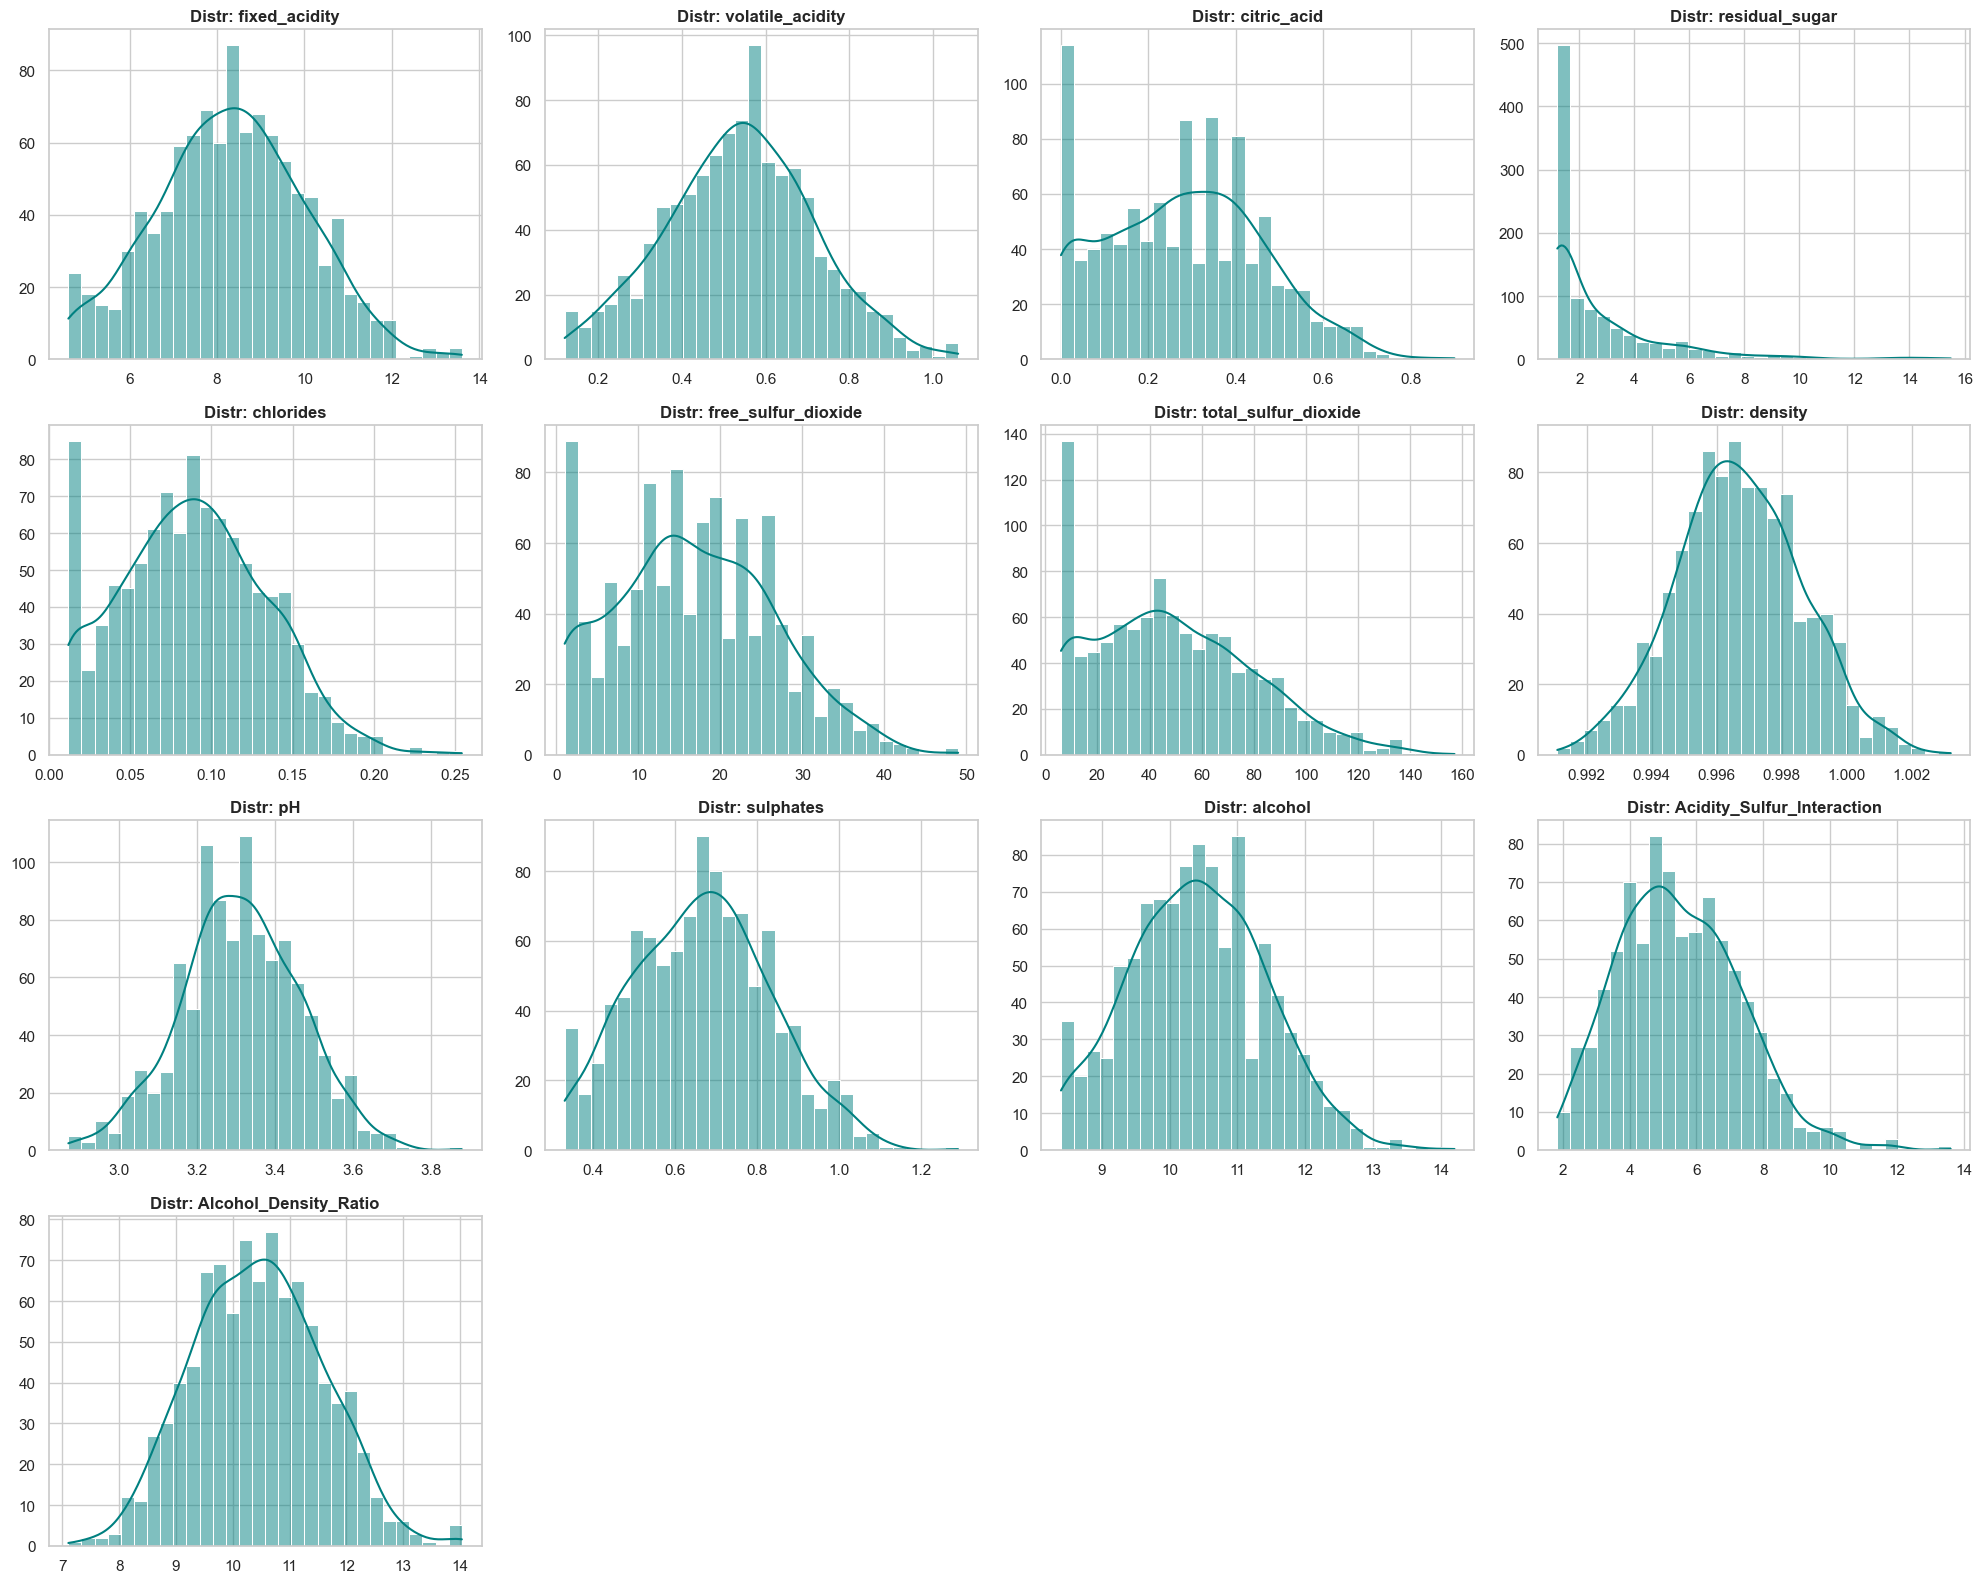

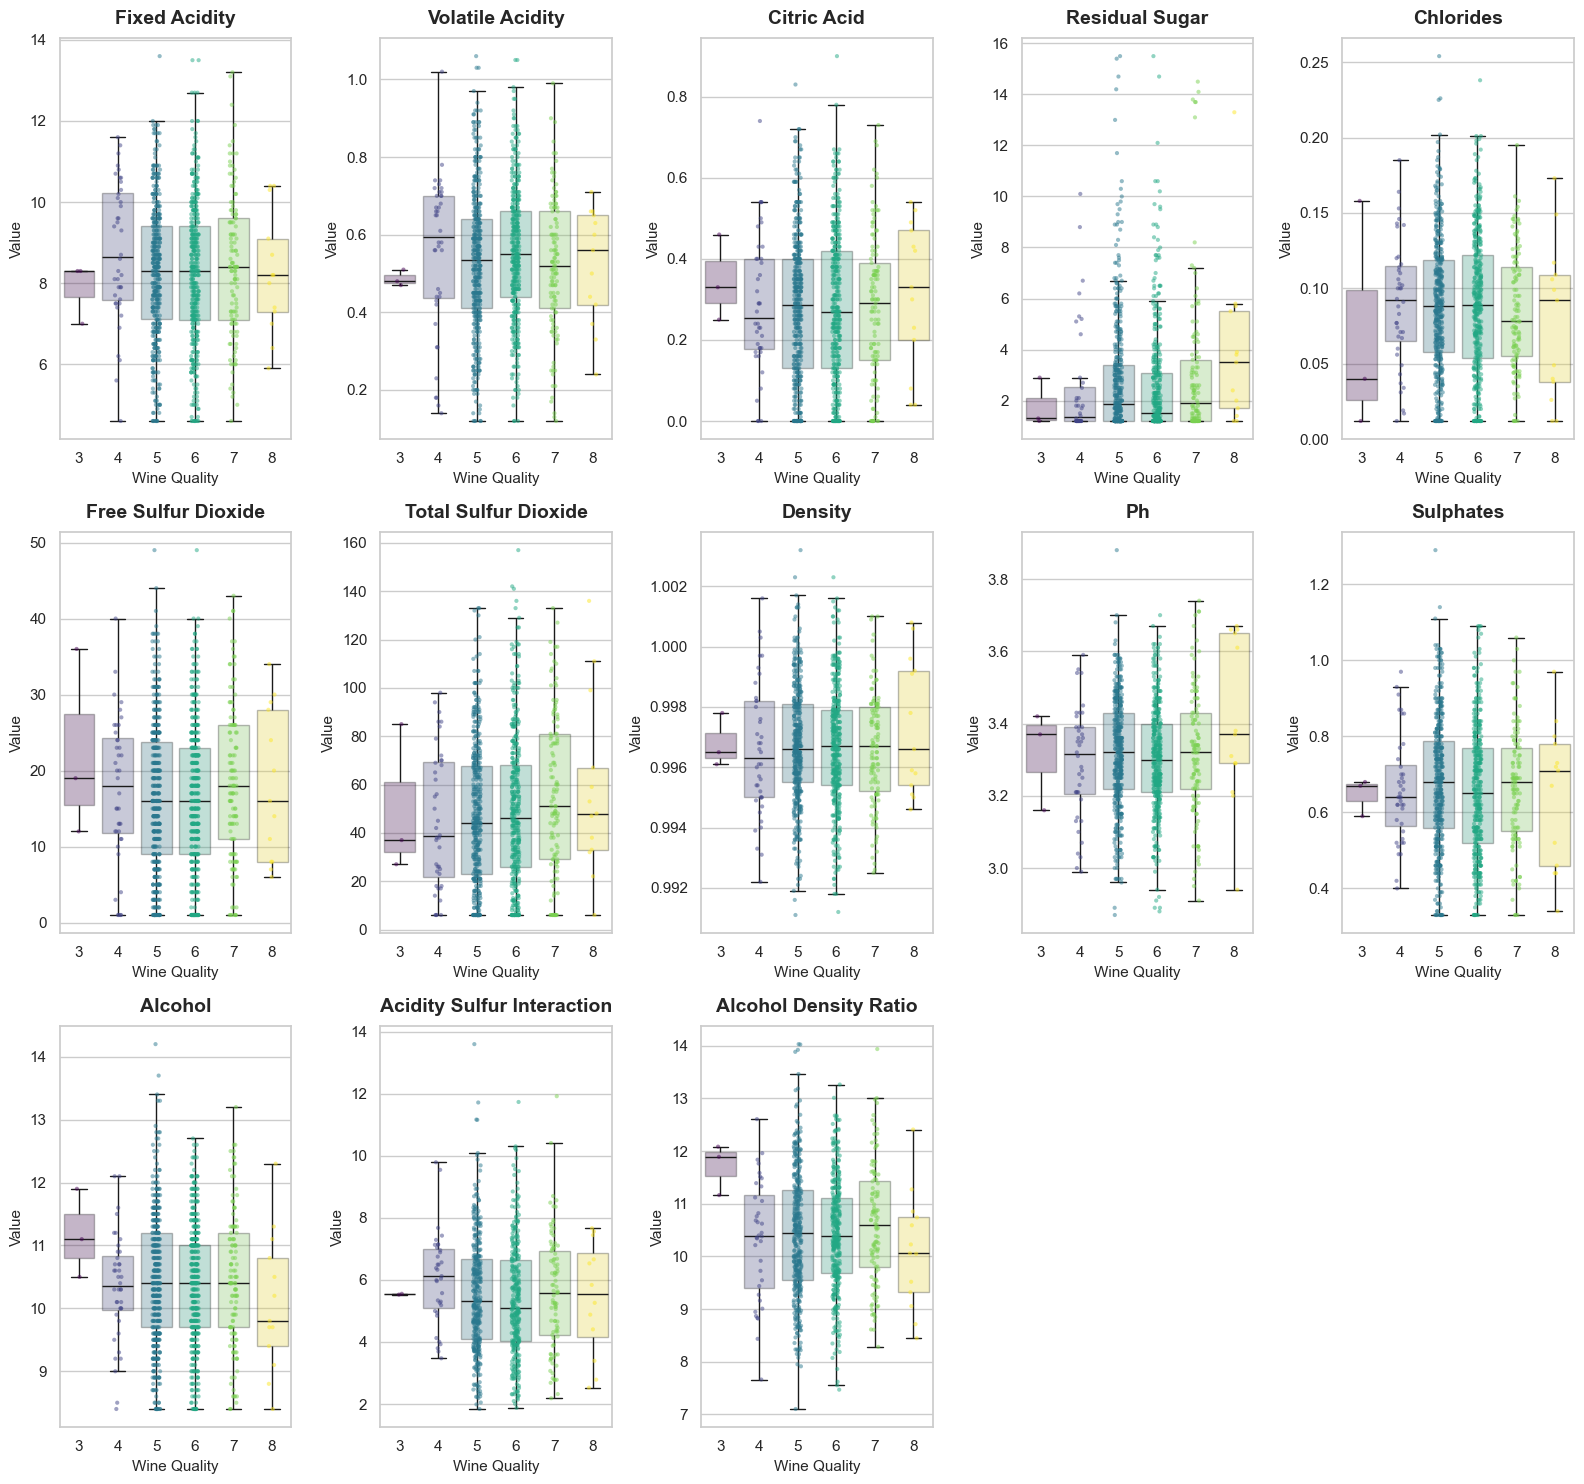



Righe originali nel dataset: 1024
Righe identificate come rumore: 145
Nuovo totale righe per l'addestramento: 879

Grafico dati senza rumore


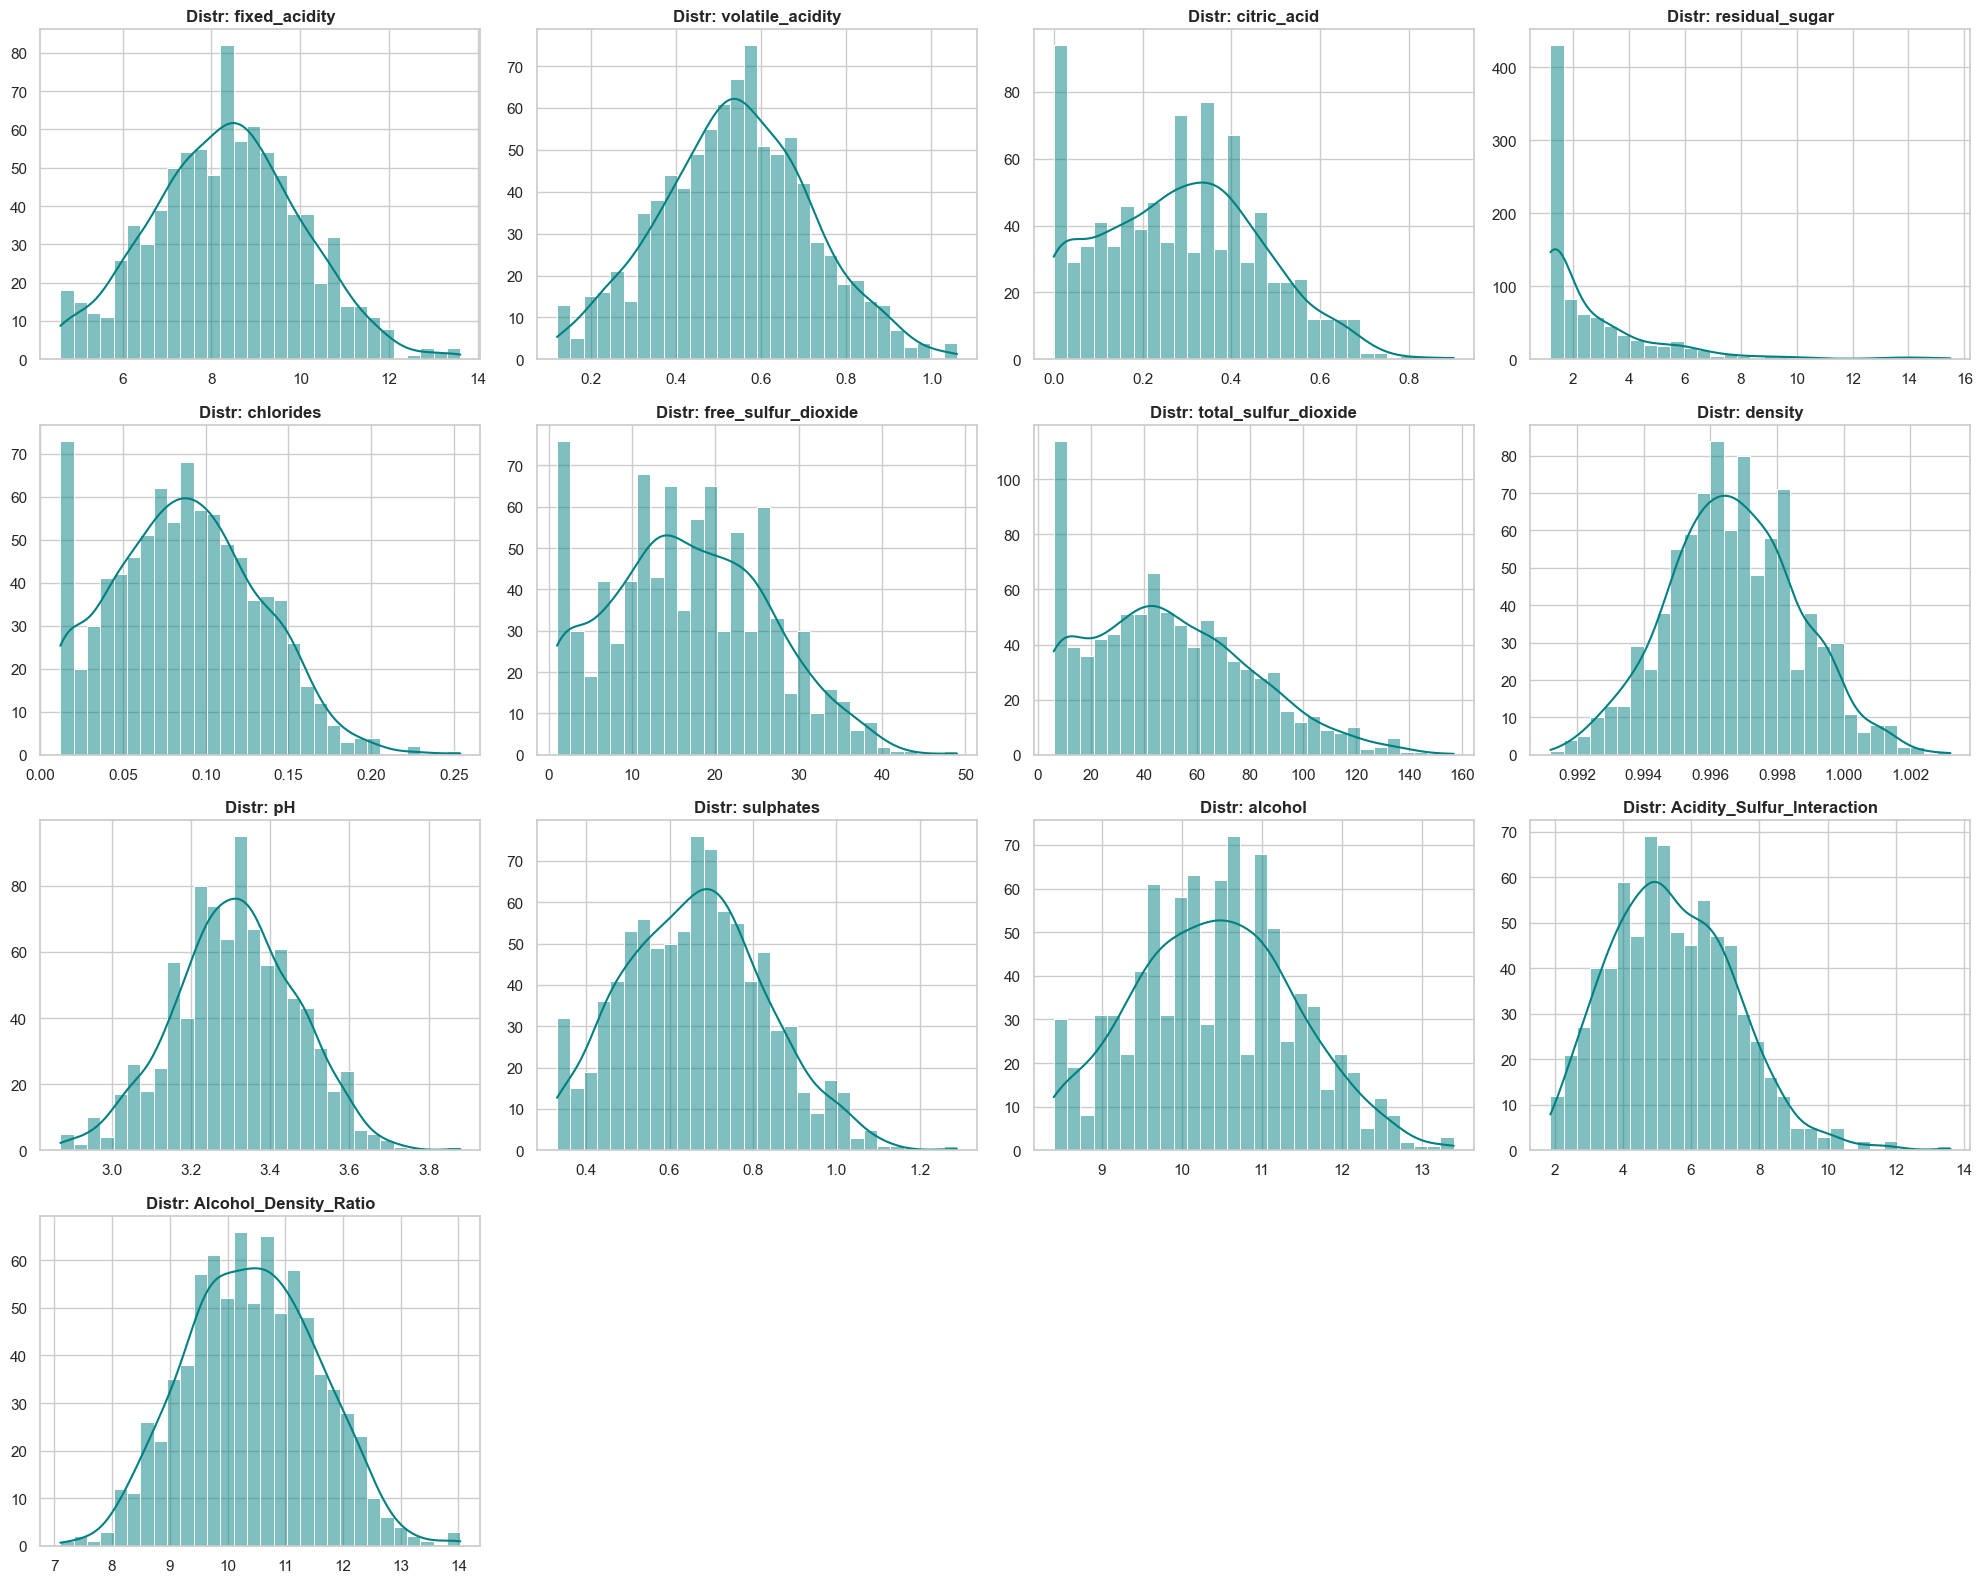

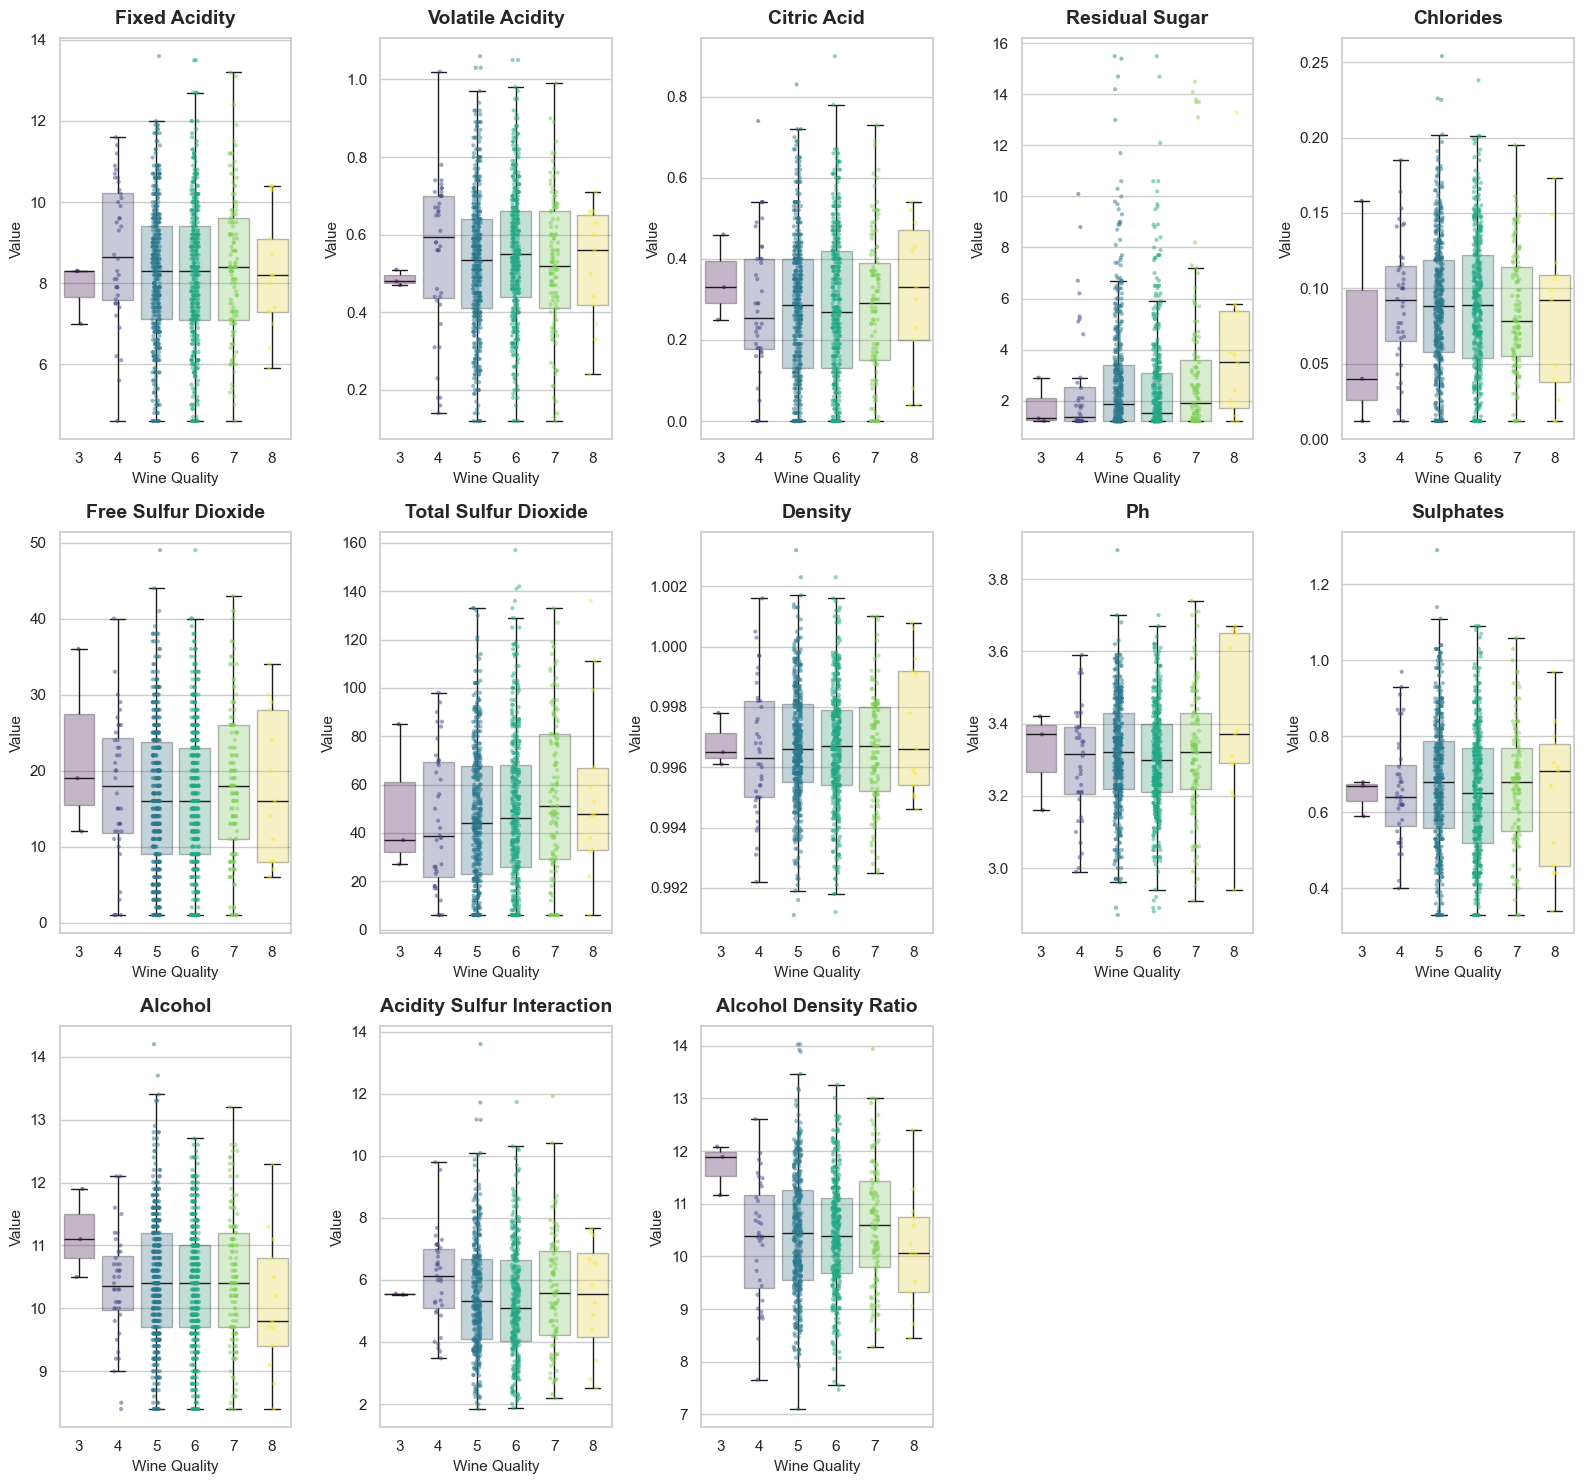

In [10]:
cols_to_drop = ['WineQuality', 'Synthetic_Noise_Flag', 'Volatile_Enhanced']

#Grafici PRIMA della pulizia
print("\nGrafico dati originali, senza alcuna pulizia")
plot_distribuzioni(train_data, cols_to_drop)

plot_chemical_features_enhanced(train_data, cols_to_drop)

################################################################################################
righe_totali = len(train_data)
#Teniamo solo le righe dove il Synthetic_Noise_flag è uguale a 0
train_data_clean = train_data[train_data['Synthetic_Noise_Flag'] == 0].copy()
righe_rimosse = righe_totali - len(train_data_clean)

print("\n")
print(f"Righe originali nel dataset: {righe_totali}")
print(f"Righe identificate come rumore: {righe_rimosse}")
print(f"Nuovo totale righe per l'addestramento: {len(train_data_clean)}")

# Grafici DOPO la pulizia
print("\nGrafico dati senza rumore")
plot_distribuzioni(train_data_clean, cols_to_drop)

plot_chemical_features_enhanced(train_data, cols_to_drop)

#### Matrice di correlazione

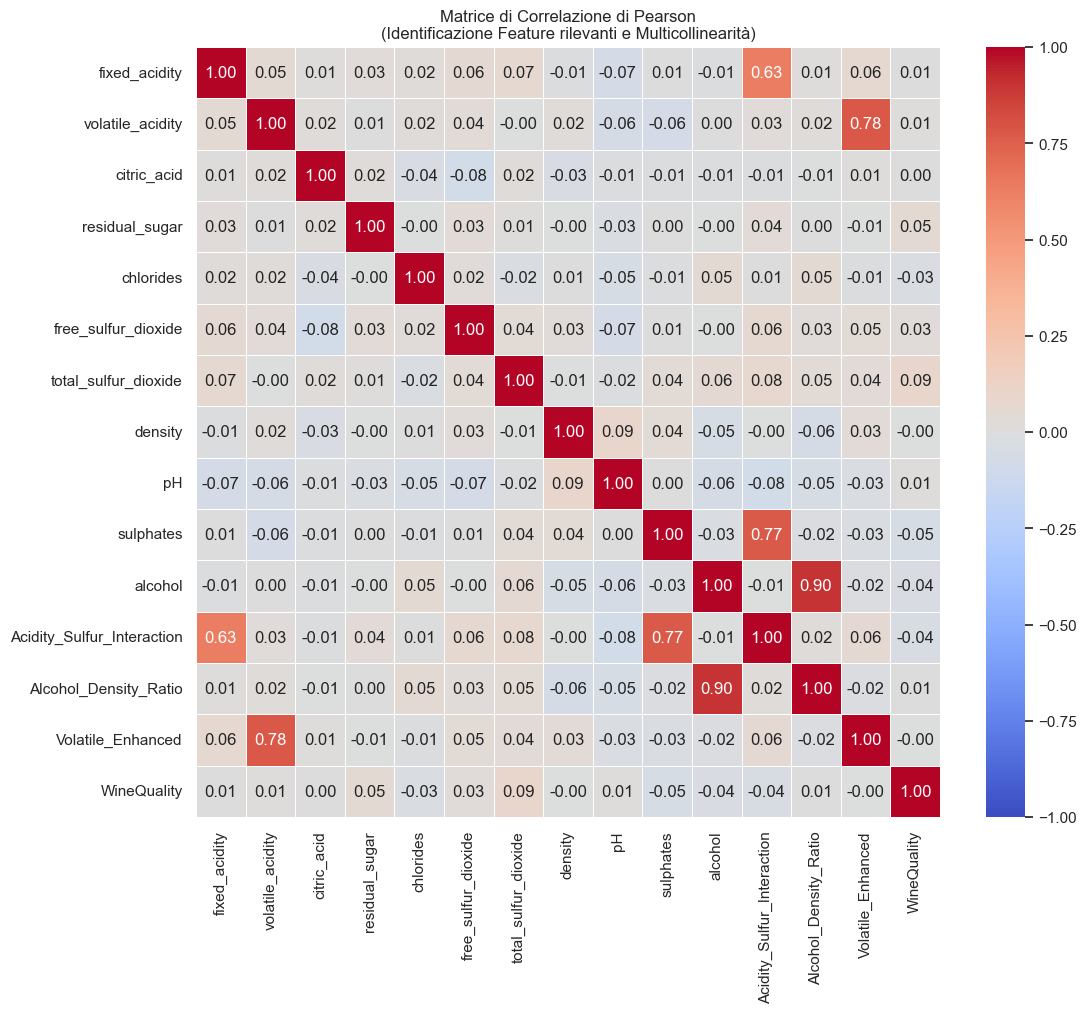

In [11]:
# Calcoliamo la matrice di correlazione sul dataset pulito (senza flag)
# Includiamo WineQuality per vedere come le feature influenzano il voto
corr_matrix = train_data_clean.drop(columns=['Synthetic_Noise_Flag']).corr()

# Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt=".2f", 
            cmap='coolwarm', 
            vmin=-1, 
            vmax=1, 
            center=0, 
            linewidths=0.5)

plt.title('Matrice di Correlazione di Pearson\n(Identificazione Feature rilevanti e Multicollinearità)')
plt.show()

- *Alcohol e Alcohol_Density_Ratio* ($r = 0.90$): C'è una correlazione quasi perfetta. Tenere entrambe è ridondante. 
- *Volatile_acidity e Volatile_Enhanced* ($r = 0.78$).
- *Sulphates e Acidity_Sulfur_Interaction* ($r = 0.77$).

Allora procediamo scegliendo una sola variabile per ogni coppia, tenendo quella che ha la correlazione più alta con il target (WineQuality) o quella che ha più senso fisico/chimico

Coppia 1: Alcohol vs. Alcohol_Density_Ratio: Alcohol_Density_Ratio a logica è sicuramente calcolata come $\text{alcohol} / \text{density}$.

Coppia 2: Volatile_acidity vs. Volatile_Enhanced: Il termine "Enhanced" suggerisce che la variabile originale sia stata semplicemente trasformata in qualche modo. 

Coppia 3: Sulphates vs. Acidity_Sulfur_Interaction: Questa è una tipica feature di interazione che solitamente si ottiene moltiplicando due variabili tra loro ($\text{sulphates} \times \text{fixed\_acidity}$).

Per la Feature Selection teniamo solo le originali: 
alcohol, volatile_acidity, sulphates.

In [19]:
redundant_features= [
    'Alcohol_Density_Ratio',      # Correlata al 90% con alcohol
    'Volatile_Enhanced',          # Correlata al 78% con volatile_acidity
    'Acidity_Sulfur_Interaction'  # Correlata al 77% con sulphates
]

# creiamo il dataset (con rumore) con solo le feature originali
train_data_reduced = train_data.drop(columns=redundant_features).copy()
train_data_reduced = train_data_reduced.drop(columns=["Synthetic_Noise_Flag"]).copy() #elimino il flag binario

# creiamo il datstet (senza rumore) con solo le feature originali
train_data_clean_reduced = train_data_clean.drop(columns=redundant_features).copy()
train_data_clean_reduced = train_data_clean_reduced.drop(columns=["Synthetic_Noise_Flag"]).copy() #elimino il flag binario

train_data_reduced.head()
#train_data_clean_reduced.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,WineQuality
0,7.1,0.45,0.62,6.5,0.012,25,71,1.0013,3.49,0.93,9.1,6
1,9.3,0.54,0.43,7.4,0.012,17,76,0.9953,3.31,0.65,11.5,5
2,8.8,0.45,0.28,1.2,0.090,15,24,0.9956,3.53,0.74,9.8,5
3,11.1,0.48,0.45,5.6,0.102,12,79,0.9964,3.21,0.52,10.8,6
4,9.2,0.61,0.00,4.9,0.155,9,54,0.9945,3.29,0.73,9.4,6


a questo punto abbiamo due versioni del dataset originale: 
- 1 versione: train_data -> train_data_reduced 
- 2 versione: train_data_clean_reduced

# Trasformazioni dei dati ad hoc e pipelines per i singoli algoritmi

# 1) knn

In [20]:
# Scenario con rumore ma colonne ridondanti rimosse
X_train_reduced_knn = train_data_reduced.drop(columns=['WineQuality'])
y_train_reduced_knn = train_data_reduced['WineQuality']

# Scenario senza rumore e colonne ridondanti rimosse
X_train_clean_reduced_knn = train_data_clean_reduced.drop(columns=['WineQuality'])
y_train_clean_reduced_knn = train_data_clean_reduced['WineQuality']

# Test set
X_test_reduced_knn = test_data.drop(columns=['WineQuality', 'Synthetic_Noise_Flag']+redundant_features)
y_test_reduced_knn = test_data['WineQuality']

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif
from functools import partial

mi = partial(mutual_info_classif, random_state=RANDOM_STATE)


preprocessing_steps = [
        ('imputer', SimpleImputer(strategy='median')),      # riempiamo i valori NaN
        ('scaler', StandardScaler()),                        # standardizzazione 
        ('feature_selection', SelectKBest(score_func=mi, k=7))  # k temporaneo
    ]

pipeline = Pipeline(steps=
   preprocessing_steps + 
    [('knn', KNeighborsClassifier()) 
])

In [24]:
def apply_pipeline_preprocessing(X_train, X_test, y_train, pipeline):   
    preprocessor = pipeline[:-1]

    # Il modello calcola media e deviazioni standard e poi trasforma i dati, è una matrice
    X_train_prep_array = preprocessor.fit_transform(X_train,y_train) 

    # Recuperiamo i nomi delle feature che sono sopravvissute al SelectKBest
    selected_features = X_train.columns[preprocessor.named_steps['feature_selection'].get_support()]
    
    # Riconversione in DataFrame 
    X_train_prep_df = pd.DataFrame(X_train_prep_array, columns=selected_features, index=X_train.index)
    
    
    X_test_prep_array = preprocessor.transform(X_test)
    X_test_prep_df = pd.DataFrame(X_test_prep_array, columns=selected_features, index=X_test.index)
    
       
    return X_train_prep_df, X_test_prep_df, preprocessor


In [25]:
print("Preprocessing Scenario con rumore") 
X_train_prep_knn, X_test_prep_knn, preprocessor_noise_knn = apply_pipeline_preprocessing(X_train_reduced_knn, X_test_reduced_knn, y_train_reduced_knn, pipeline)


print("Preprocessing Scenario senza rumore")
X_train_clean_prep_knn, X_test_clean_prep_knn, preprocessor_clean_knn = apply_pipeline_preprocessing(X_train_clean_reduced_knn, X_test_reduced_knn, y_train_clean_reduced_knn, pipeline)

Preprocessing Scenario con rumore
Preprocessing Scenario senza rumore


#### Scelta del parametro K
- Se $K$ è troppo basso (es. $K=1$), il modello diventa troppo sensibile alle anomalie (Overfitting).
- Se $K$ è troppo alto (es. $K=100$), il modello guarderà un raggio così ampio da confondere le classi (Underfitting).

Ricerca del K ottimale
Analisi Scenario 1: Ridotto (con rumore)
Analisi Scenario 2: Clean + Ridotto (senza rumore)

Risultati:
- K Ottimo (con rumore): 11
- K Ottimo (senza rumore): 7


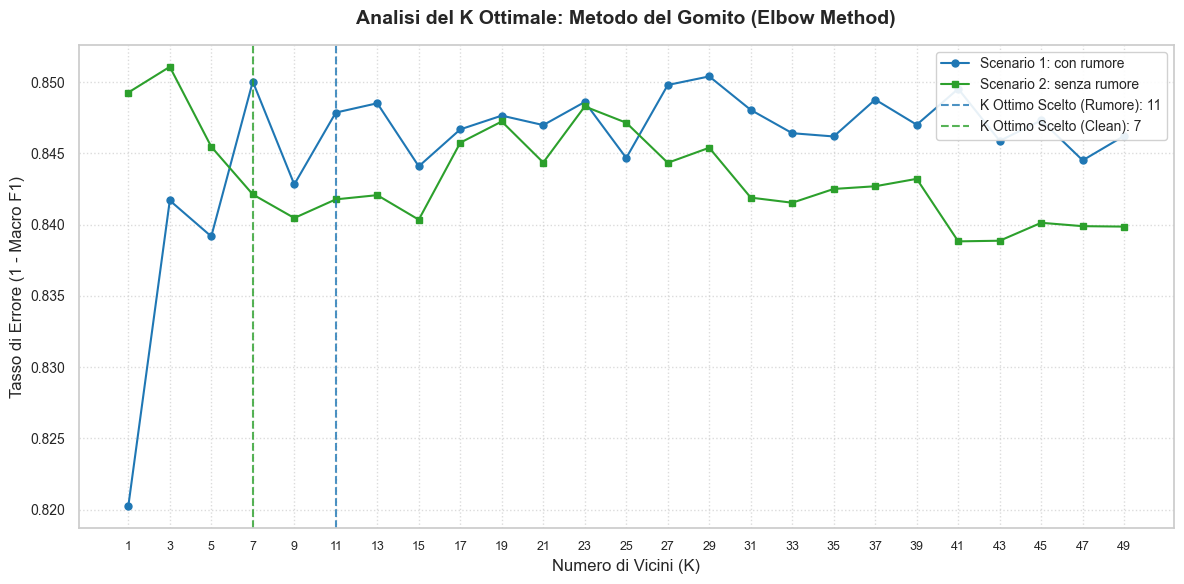

In [27]:
# DEFINIZIONE DEI VALORI DI K
k_values = range(1, 50, 2)
epsilon = 0.002

print("Ricerca del K ottimale")
def find_optimal_k(X, y, pipeline, k_values, epsilon, random_state=RANDOM_STATE):
    
    error_rates = []

    cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state)

    for k in k_values:
        # Aggiorna K nella pipeline
        pipeline.set_params(knn__n_neighbors=k)
        
        # Cross-Validation a 3 fold con Macro F1
        scores = cross_val_score(pipeline, X, y, cv=cv_strategy, scoring='f1_macro')
        
        # Calcolo tasso di errore (1 - media F1)
        error_rates.append(1 - scores.mean())
    
    # Calcolo del "gomito" (Elbow)
    error_rates = np.array(error_rates)
    diffs = np.abs(np.diff(error_rates))
    
    k_ottimo = list(k_values)[-1]  # Fallback all'ultimo valore
    for i in range(1, len(diffs)):
        if diffs[i] < epsilon:
            k_ottimo = list(k_values)[i]
            break
            
    return k_ottimo, error_rates

# ESECUZIONE SUI DUE SCENARI
# Scenario con rumore
print("Analisi Scenario 1: Ridotto (con rumore)")
k_opt_reduced, errors_reduced = find_optimal_k(X_train_reduced_knn, y_train_reduced_knn, pipeline, k_values, epsilon, random_state=RANDOM_STATE)

# Scenario senza rumore
print("Analisi Scenario 2: Clean + Ridotto (senza rumore)")
k_opt_clean, errors_clean = find_optimal_k(X_train_clean_reduced_knn, y_train_clean_reduced_knn, pipeline, k_values, epsilon, random_state=RANDOM_STATE)

print(f"\nRisultati:\n- K Ottimo (con rumore): {k_opt_reduced}")
print(f"- K Ottimo (senza rumore): {k_opt_clean}")


# Plot
plt.figure(figsize=(12, 6))
plt.plot(list(k_values), errors_reduced, marker='o', markersize=5, linestyle='-', 
         label='Scenario 1: con rumore', color='tab:blue')
plt.plot(list(k_values), errors_clean, marker='s', markersize=5, linestyle='-', 
         label='Scenario 2: senza rumore', color='tab:green')
plt.axvline(x=k_opt_reduced, color='tab:blue', linestyle='--', alpha=0.8, 
            label=f'K Ottimo Scelto (Rumore): {k_opt_reduced}')
plt.axvline(x=k_opt_clean, color='tab:green', linestyle='--', alpha=0.8, 
            label=f'K Ottimo Scelto (Clean): {k_opt_clean}')
plt.title('Analisi del K Ottimale: Metodo del Gomito (Elbow Method)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Numero di Vicini (K)', fontsize=12)
plt.ylabel('Tasso di Errore (1 - Macro F1)', fontsize=12)
plt.xticks(list(k_values), fontsize=9)
plt.yticks(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='upper right', fontsize=10, framealpha=0.9)

plt.tight_layout()
plt.show()

#### Addestramento dei modelli knn

In [29]:
from sklearn.base import clone

# Creiamo due pipeline indipendenti per non sovrascrivere
pipeline_noise = clone(pipeline)
pipeline_clean = clone(pipeline)

# Impostiamo il K ottimale su entrambe
pipeline_noise.set_params(knn__n_neighbors=k_opt_reduced)
pipeline_clean.set_params(knn__n_neighbors=k_opt_clean)

# Addestramento con dati rumorosi
pipeline_noise.fit(X_train_reduced_knn, y_train_reduced_knn)
y_pred_reduced_knn = pipeline_noise.predict(X_test_reduced_knn)

# Addestramento con dati puliti
pipeline_clean.fit(X_train_clean_reduced_knn, y_train_clean_reduced_knn)
y_pred_clean_reduced_knn = pipeline_clean.predict(X_test_reduced_knn)

#### Valutazione modelli knn

In [30]:
print("PERFORMANCE SCENARIO DATI PULITI")
print(classification_report(y_test_reduced_knn, y_pred_clean_reduced_knn))

PERFORMANCE SCENARIO DATI PULITI
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.33      0.10      0.15        10
           5       0.43      0.56      0.49       110
           6       0.41      0.40      0.41       102
           7       0.22      0.07      0.10        30
           8       0.00      0.00      0.00         3

    accuracy                           0.41       256
   macro avg       0.23      0.19      0.19       256
weighted avg       0.39      0.41      0.39       256



C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

In [31]:
print("PERFORMANCE SCENARIO DATI CON RUMORE")
print(classification_report(y_test_reduced_knn, y_pred_reduced_knn))

PERFORMANCE SCENARIO DATI CON RUMORE
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.50      0.73      0.59       110
           6       0.49      0.45      0.47       102
           7       0.50      0.03      0.06        30
           8       0.00      0.00      0.00         3

    accuracy                           0.50       256
   macro avg       0.25      0.20      0.19       256
weighted avg       0.47      0.50      0.45       256



C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

#### Matrice di confusione per il knn

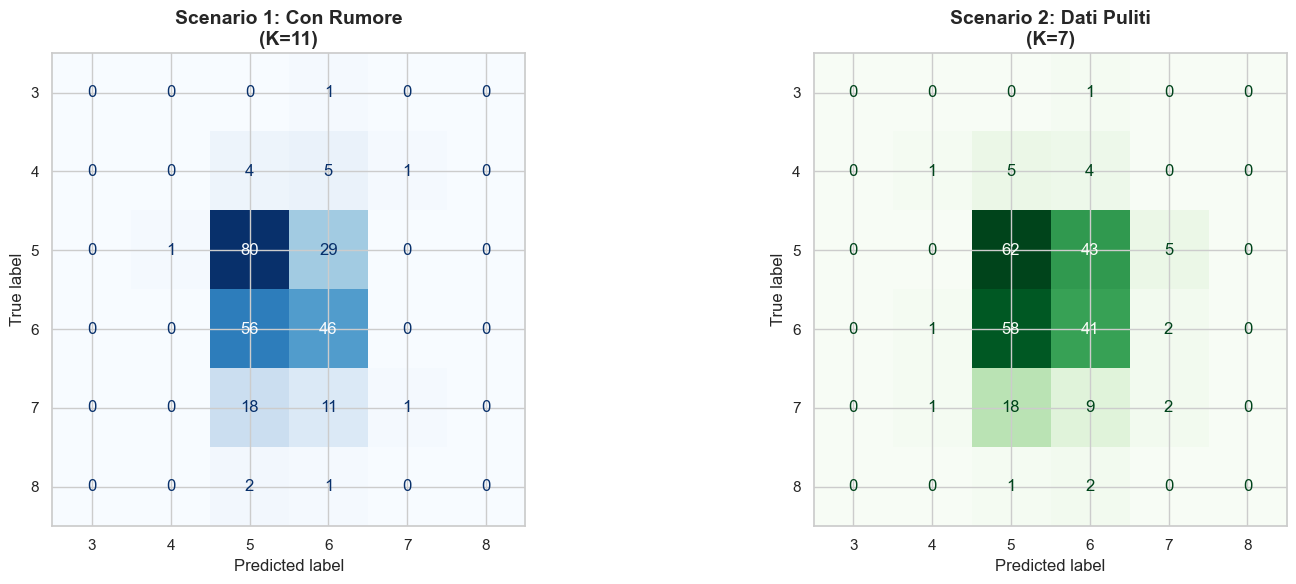

In [35]:
# Calcolo delle matrici di confusione
cm_noise = confusion_matrix(y_test_reduced_knn, y_pred_reduced_knn)
cm_clean = confusion_matrix(y_test_reduced_knn, y_pred_clean_reduced_knn)

# Creazione della figura con due subplot (1 riga, 2 colonne)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot Scenario con Rumore
disp_noise = ConfusionMatrixDisplay(confusion_matrix=cm_noise, 
                                    display_labels=np.unique(y_test_reduced_knn))
disp_noise.plot(ax=ax[0], cmap='Blues', values_format='d', colorbar=False)
ax[0].set_title(f'Scenario 1: Con Rumore\n(K={k_opt_reduced})', fontsize=14, fontweight='bold')

# Plot Scenario Dati Puliti
disp_clean = ConfusionMatrixDisplay(confusion_matrix=cm_clean, 
                                    display_labels=np.unique(y_test_reduced_knn))
disp_clean.plot(ax=ax[1], cmap='Greens', values_format='d', colorbar=False)
ax[1].set_title(f'Scenario 2: Dati Puliti\n(K={k_opt_clean})', fontsize=14, fontweight='bold')

# Miglioramento layout
plt.tight_layout()
plt.show()

# 2) Regressione Logistica

In [ ]:
train_rl = train_data.copy()
test_rl = test_data.copy()

train_rl = train_rl[train_rl['Synthetic_Noise_Flag'] == 0]

for col in train_rl.select_dtypes(include=np.number).columns:
    train_rl[col] = train_rl[col].fillna(train_rl[col].median())

for col in test_rl.select_dtypes(include=np.number).columns:
    test_rl[col] = test_rl[col].fillna(test_rl[col].median())

In [74]:
X_train_rl = train_rl.drop(columns=["WineQuality"])
y_train_rl = train_rl["WineQuality"]

X_test_rl = test_rl.drop(columns=["WineQuality"])
y_test_rl = test_rl["WineQuality"]

In [75]:
scaler = MinMaxScaler()

X_train_scaled_rl = scaler.fit_transform(X_train_rl)
X_test_scaled_rl = scaler.transform(X_test_rl)

X_train_scaled_rl = pd.DataFrame(X_train_scaled_rl, columns=X_train_rl.columns)
X_test_scaled_rl = pd.DataFrame(X_test_scaled_rl, columns=X_test_rl.columns)

In [76]:
model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs"
)


Risultati Cross Validation:
Accuracy per ogni fold: [0.42690058 0.42521994 0.39882698]
Accuracy media: 0.4169825018721453
Deviazione standard: 0.012856214730918771


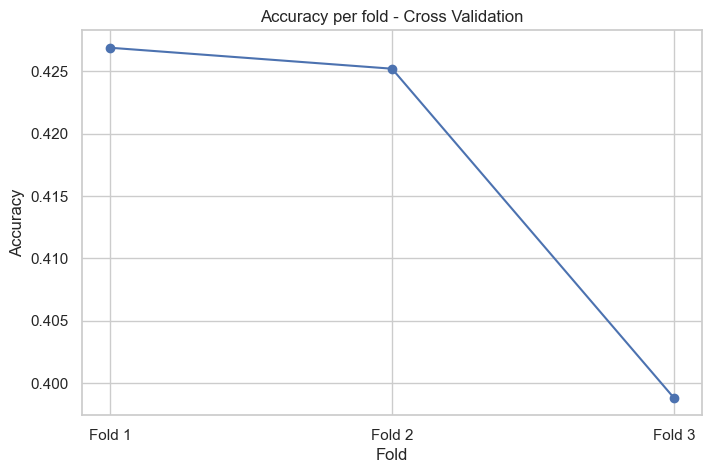

In [77]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X_train_scaled_rl,
    y_train_rl,
    cv=cv,
    scoring="accuracy"
)

print("\nRisultati Cross Validation:")
print("Accuracy per ogni fold:", scores)
print("Accuracy media:", scores.mean())
print("Deviazione standard:", scores.std())

plt.figure(figsize=(8, 5))
plt.plot(scores, marker="o")
plt.title("Accuracy per fold - Cross Validation")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.xticks(range(len(scores)), ["Fold 1", "Fold 2", "Fold 3"])
plt.show()


#### Regressione losgistica addestramento

In [78]:
model.fit(X_train_scaled_rl, y_train_rl)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

#### Valutazione della regressione logistica

In [79]:
y_pred_rl = model.predict(X_test_scaled_rl)

accuracy_rl = accuracy_score(y_test_rl, y_pred_rl)

print("\nAccuracy sul test set:", accuracy_rl)

print("\nMatrice di confusione - Test:")
print(confusion_matrix(y_test_rl, y_pred_rl))

print("\nClassification report - Test:")
print(classification_report(y_test_rl, y_pred_rl, zero_division=0))



Accuracy sul test set: 0.45703125

Matrice di confusione - Test:
[[ 0  0  0  1  0  0]
 [ 0  0  8  2  0  0]
 [ 0  0 69 41  0  0]
 [ 0  0 54 48  0  0]
 [ 0  0 25  5  0  0]
 [ 0  0  3  0  0  0]]

Classification report - Test:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.43      0.63      0.51       110
           6       0.49      0.47      0.48       102
           7       0.00      0.00      0.00        30
           8       0.00      0.00      0.00         3

    accuracy                           0.46       256
   macro avg       0.15      0.18      0.17       256
weighted avg       0.38      0.46      0.41       256



#### Matrice di confusione per la regressione logistica

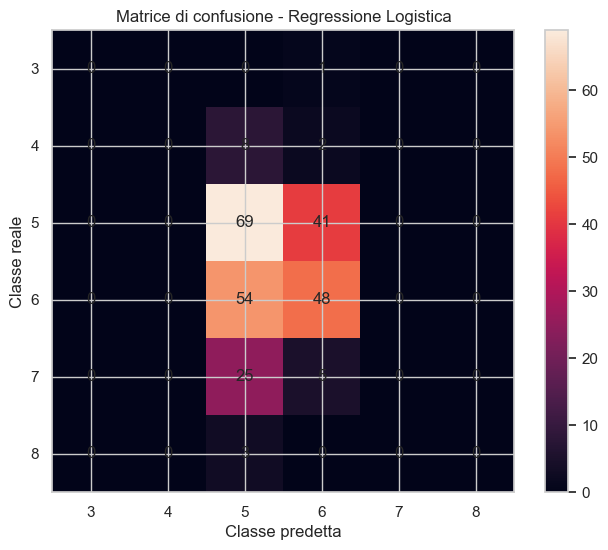

In [80]:
cm = confusion_matrix(y_test_rl, y_pred_rl)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title("Matrice di confusione - Regressione Logistica")
plt.xlabel("Classe predetta")
plt.ylabel("Classe reale")
plt.colorbar()

classi = sorted(y_train_rl.unique())
plt.xticks(range(len(classi)), classi)
plt.yticks(range(len(classi)), classi)

for i in range(len(cm)):
    for j in range(len(cm[i])):
        plt.text(j, i, cm[i][j], ha="center", va="center")

plt.show()

#### Ripetiamo l'addestramento della regressione logistica senza la colonna Synthetic_Noise_Flag

In [81]:
X_train_nf_rl = train_rl.drop(columns=["WineQuality", "Synthetic_Noise_Flag"], errors="ignore")
y_train_nf_rl = train_rl["WineQuality"]

X_test_nf_rl = test_rl.drop(columns=["WineQuality", "Synthetic_Noise_Flag"], errors="ignore")
y_test_nf_rl = test_rl["WineQuality"]

In [84]:
scaler_nf = MinMaxScaler()
X_train_nf_scaled_rl = scaler_nf.fit_transform(X_train_nf_rl)
X_test_nf_scaled_rl = scaler_nf.transform(X_test_nf_rl)

##########################################################
model_nf = LogisticRegression(max_iter=5000)

scores_nf = cross_val_score(
    model_nf,
    X_train_nf_scaled_rl,
    y_train_nf_rl,
    cv=cv,
    scoring="accuracy"
)

print("\n=== SENZA FLAG ===")
print("Accuracy CV media:", scores_nf.mean())

############################################################
model_nf.fit(X_train_nf_scaled_rl, y_train_nf_rl)

y_pred_nf_rl = model_nf.predict(X_test_nf_scaled_rl)
accuracy_nf_rl = accuracy_score(y_test_nf_rl, y_pred_nf_rl)

print("Accuracy test senza flag:", accuracy_nf_rl)



=== SENZA FLAG ===
Accuracy CV media: 0.4326084843911669
Accuracy test senza flag: 0.453125


# 3) Random Forest

In [ ]:
train_rf = train_data.copy()
test_rf = test_data.copy()

train_rf = train_rf[train_rf['Synthetic_Noise_Flag'] == 0]

X_rf = train_rf.drop(columns=["WineQuality", "Synthetic_Noise_Flag", "Volatile_Enhanced"])
y_rf = train_rf["WineQuality"]

print("Distribuzione originale delle classi:")
print(y_rf.value_counts().sort_index())

Distribuzione originale delle classi:
WineQuality
3      3
4     40
5    438
6    409
7    121
8     13
Name: count, dtype: int64


In [90]:
X_clean = X_rf.copy()

# Colonne numeriche su cui applicare l'imputazione
numeric_cols = X_clean.select_dtypes(include=["float64", "int64"]).columns

imputer = SimpleImputer(strategy="median") #Gestione dei missing values con la media
X_clean[numeric_cols] = imputer.fit_transform(X_clean[numeric_cols])

#### Eseguiamo l'oversampling delle classi minoritarie (3, 4, 7, 8) con RESAMPLE portandole allo stesso numero di esempi della classe più numerosa (438)

In [91]:
# Dimensione target: numero massimo di esempi per classe
max_count = y_rf.value_counts().max()

X_balanced = []
y_balanced = []

for label in sorted(y_rf.unique()):
    X_class = X_clean[y_rf == label]
    y_class = y_rf[y_rf == label]
    
    if len(X_class) < max_count:
        # Oversampling con rimpiazzo
        X_res, y_res = resample(X_class, y_class,
                                 replace=True,
                                 n_samples=max_count,
                                 random_state=42)
    else:
        X_res, y_res = X_class, y_class
    
    X_balanced.append(X_res)
    y_balanced.append(y_res)

X_balanced = pd.concat(X_balanced)
y_balanced = pd.concat(y_balanced)

print("Distribuzione dopo augmentation:")
print(y_balanced.value_counts().sort_index())

Distribuzione dopo augmentation:
WineQuality
3    438
4    438
5    438
6    438
7    438
8    438
Name: count, dtype: int64


In [92]:
X_train, X_val, y_train, y_val = train_test_split(
    X_balanced, y_balanced,
    test_size=0.2,
    random_state=42,
    stratify=y_balanced
)


############################################
param_grid = {
    "n_estimators": [100, 250, 500],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Migliori parametri:", grid_search.best_params_)
print("Miglior F1 macro (CV media):", grid_search.best_score_)


Migliori parametri: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 500}
Miglior F1 macro (CV media): 0.8389172871503683


#### Valutazione del random forest

In [93]:
best_model = grid_search.best_estimator_

# Predizioni cross‑validate
y_pred_cv = cross_val_predict(best_model, X_balanced, y_balanced, cv=cv)

accuracy_cv = accuracy_score(y_balanced, y_pred_cv)
precision_cv = precision_score(y_balanced, y_pred_cv, average="macro", zero_division=0)
recall_cv = recall_score(y_balanced, y_pred_cv, average="macro", zero_division=0)
f1_cv = f1_score(y_balanced, y_pred_cv, average="macro", zero_division=0)

print("Accuracy (CV):", accuracy_cv)
print("Precision macro (CV):", precision_cv)
print("Recall macro (CV):", recall_cv)
print("F1 macro (CV):", f1_cv)
print("\nClassification report (CV):")
print(classification_report(y_balanced, y_pred_cv, zero_division=0))

Accuracy (CV): 0.8801369863013698
Precision macro (CV): 0.8790217104403237
Recall macro (CV): 0.8801369863013698
F1 macro (CV): 0.8788783992246874

Classification report (CV):
              precision    recall  f1-score   support

           3       1.00      1.00      1.00       438
           4       0.99      1.00      0.99       438
           5       0.67      0.72      0.69       438
           6       0.73      0.63      0.68       438
           7       0.91      0.93      0.92       438
           8       0.98      1.00      0.99       438

    accuracy                           0.88      2628
   macro avg       0.88      0.88      0.88      2628
weighted avg       0.88      0.88      0.88      2628



#### Matrice di confusione per il random forest

In [94]:
classi = sorted(y_balanced.unique())
conf_matrix = confusion_matrix(y_balanced, y_pred_cv, labels=classi)

conf_df = pd.DataFrame(conf_matrix, index=classi, columns=classi)
conf_df.index.name = "Classe reale"
conf_df.columns.name = "Classe predetta"
conf_df

Classe predetta,3,4,5,6,7,8
Classe reale,,,,,,
3,438,0,0,0,0,0
4,0,438,0,0,0,0
5,0,4,315,94,22,3
6,0,1,137,278,17,5
7,0,1,20,11,406,0
8,0,0,0,0,0,438


# 4) PCA + knn, regressione logistica e random forest

In [ ]:
df_train = train_data.copy()
df_test = test_data.copy()

df_train = df_train[df_train['Synthetic_Noise_Flag'] == 0]

print("Valori mancanti nel training set:\n", df_train.isnull().sum().sum())
print("Valori mancanti nel test set:\n", df_test.isnull().sum().sum())

for col in df_train.select_dtypes(include=np.number).columns:
    df_train[col] = df_train[col].fillna(df_train[col].median())

for col in df_test.select_dtypes(include=np.number).columns:
    df_test[col] = df_test[col].fillna(df_test[col].median())

print("Valori mancanti nel training set:\n", df_train.isnull().sum().sum())
print("Valori mancanti nel test set:\n", df_test.isnull().sum().sum())

Valori mancanti nel training set:
 267
Valori mancanti nel test set:
 78
Valori mancanti nel training set:
 0
Valori mancanti nel test set:
 0


In [26]:
feature_cols = [col for col in df_train.columns if col not in ['WineQuality', 'Synthetic_Noise_Flag', 'Volatile_Enhanced']]
X_train = df_train[feature_cols].copy()
y_train = df_train['WineQuality'].copy()

X_test = df_test[feature_cols].copy()
y_test = df_test['WineQuality'].copy()

#### Standardizzazione pre pca

In [27]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

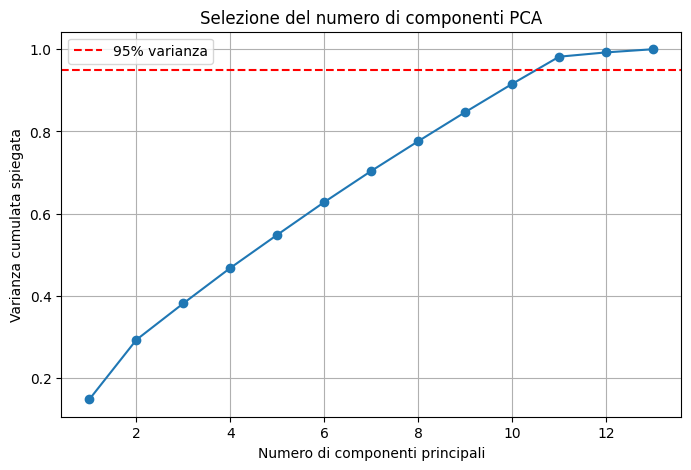

In [28]:
pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)

# Varianza spiegata
var_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

plt.figure(figsize=(8,5))
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% varianza')
plt.xlabel('Numero di componenti principali')
plt.ylabel('Varianza cumulata spiegata')
plt.title('Selezione del numero di componenti PCA')
plt.legend()
plt.grid()
plt.show()

Scegliamo il numero di componenti che spiega almeno il 95% della varianza

In [29]:
n_components = np.argmax(cum_var >= 0.95) + 1
print(f"Componenti PCA per il 95% della varianza: {n_components}")

# Riapplichiamo PCA con il numero scelto
pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

Componenti PCA per il 95% della varianza: 11


#### Random forest + pca

In [30]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(rf, param_grid_rf, cv=StratifiedKFold(5), 
                       scoring='accuracy', n_jobs=-1, verbose=1)
grid_rf.fit(X_train_pca, y_train)

print("Miglior parametri RF:", grid_rf.best_params_)
print("Accuratezza su validazione (CV):", grid_rf.best_score_)

best_rf = grid_rf.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits


C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Miglior parametri RF: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Accuratezza su validazione (CV): 0.41306551889048304


#### knn + pca

In [31]:
knn = KNeighborsClassifier()

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(knn, param_grid_knn, cv=StratifiedKFold(5),
                        scoring='accuracy', n_jobs=-1, verbose=1)
grid_knn.fit(X_train_pca, y_train)

print("Miglior parametri KNN:", grid_knn.best_params_)
print("Accuratezza su validazione (CV):", grid_knn.best_score_)

best_knn = grid_knn.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Miglior parametri KNN: {'n_neighbors': 11, 'weights': 'uniform'}
Accuratezza su validazione (CV): 0.41306073648971786


C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


#### regressione logistica + pca

In [32]:
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=2000, 
                        solver='lbfgs', class_weight='balanced')
# Se la tua versione supporta multi_class, puoi aggiungere:
# multi_class='multinomial'

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10]
}

grid_lr = GridSearchCV(lr, param_grid_lr, cv=StratifiedKFold(5),
                       scoring='accuracy', n_jobs=-1, verbose=1)
grid_lr.fit(X_train_pca, y_train)

print("Miglior parametri LR:", grid_lr.best_params_)
print("Accuratezza su validazione (CV):", grid_lr.best_score_)

best_lr = grid_lr.best_estimator_

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Miglior parametri LR: {'C': 10}
Accuratezza su validazione (CV): 0.1523194643711143


C:\Users\danil\AppData\Roaming\Python\Python313\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


#### Valutazione dei modelli con pca sul test set


--- Random Forest ---
Accuratezza sul test: 0.4297
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.45      0.58      0.51       110
           6       0.41      0.45      0.43       102
           7       0.00      0.00      0.00        30
           8       0.00      0.00      0.00         3

    accuracy                           0.43       256
   macro avg       0.14      0.17      0.16       256
weighted avg       0.36      0.43      0.39       256



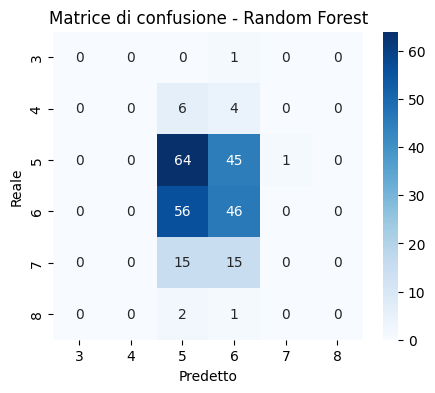


--- KNN ---
Accuratezza sul test: 0.4062
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        10
           5       0.43      0.61      0.50       110
           6       0.38      0.36      0.37       102
           7       0.00      0.00      0.00        30
           8       0.00      0.00      0.00         3

    accuracy                           0.41       256
   macro avg       0.13      0.16      0.15       256
weighted avg       0.33      0.41      0.36       256



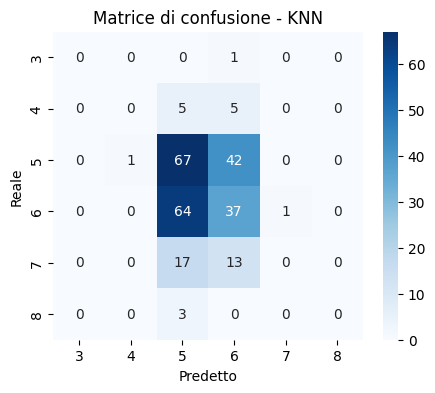


--- Regressione Logistica ---
Accuratezza sul test: 0.1797
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.05      0.40      0.10        10
           5       0.46      0.15      0.22       110
           6       0.53      0.24      0.33       102
           7       0.10      0.07      0.08        30
           8       0.00      0.00      0.00         3

    accuracy                           0.18       256
   macro avg       0.19      0.14      0.12       256
weighted avg       0.42      0.18      0.24       256



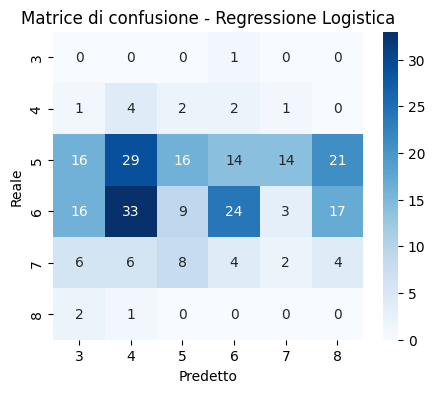

In [33]:
models = {
    'Random Forest': best_rf,
    'KNN': best_knn,
    'Regressione Logistica': best_lr
}

for name, model in models.items():
    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n--- {name} ---")
    print(f"Accuratezza sul test: {acc:.4f}")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    # Matrice di confusione
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=sorted(y_test.unique()),
                yticklabels=sorted(y_test.unique()))
    plt.title(f'Matrice di confusione - {name}')
    plt.xlabel('Predetto')
    plt.ylabel('Reale')
    plt.show()